In [112]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split , KFold , GridSearchCV , cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression , Ridge , Lasso
from sklearn.ensemble import RandomForestRegressor , HistGradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

In [ ]:
pd.set_option("display.max_columns" , None)
pd.set_option("display.float_format" , lambda x: f"{x:.3f}")


In [ ]:
df = pd.read_csv("housing.csv")

In [ ]:
df.shape

(20640, 10)

In [ ]:
df.sample(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
10271,-117.870,33.870,15.000,1898.000,476.000,1766.000,455.000,2.493,158500.000,<1H OCEAN
18994,-121.950,38.430,19.000,3011.000,551.000,1665.000,535.000,5.153,232800.000,INLAND
7774,-118.080,33.910,30.000,1366.000,460.000,920.000,410.000,0.995,159900.000,<1H OCEAN
844,-122.070,37.580,16.000,1644.000,251.000,1033.000,267.000,6.512,244300.000,NEAR BAY
10370,-117.660,33.650,13.000,8527.000,1364.000,4597.000,1393.000,6.224,237900.000,<1H OCEAN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
num_cols = df.select_dtypes(include = [np.number]).columns.tolist()
cat_cols = df.select_dtypes(include = ["object"]).columns.tolist()
print(num_cols)
print(cat_cols)

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
['ocean_proximity']


In [ ]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
#checking for encoded missing values
for col in df.columns:
  print(df[col].value_counts().head(10))


longitude
-118.310    162
-118.300    160
-118.290    148
-118.270    144
-118.320    142
-118.280    141
-118.350    140
-118.360    138
-118.190    135
-118.250    128
Name: count, dtype: int64
latitude
34.060    244
34.050    236
34.080    234
34.070    231
34.040    221
34.090    212
34.020    208
34.100    203
34.030    193
33.930    181
Name: count, dtype: int64
housing_median_age
52.000    1273
36.000     862
35.000     824
16.000     771
17.000     698
34.000     689
26.000     619
33.000     615
18.000     570
25.000     566
Name: count, dtype: int64
total_rooms
1527.000    18
1613.000    17
1582.000    17
2127.000    16
2053.000    15
1722.000    15
1607.000    15
1717.000    15
1471.000    15
1703.000    15
Name: count, dtype: int64
total_bedrooms
280.000    55
331.000    51
345.000    50
343.000    49
393.000    49
394.000    48
348.000    48
328.000    48
272.000    47
309.000    47
Name: count, dtype: int64
population
891.000     25
1052.000    24
761.000     24
850.000  

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.000,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
latitude,20640.000,35.632,2.136,32.540,33.930,34.260,37.710,41.950
housing_median_age,20640.000,28.639,12.586,1.000,18.000,29.000,37.000,52.000
total_rooms,20640.000,2635.763,2181.615,2.000,1447.750,2127.000,3148.000,39320.000
total_bedrooms,20433.000,537.871,421.385,1.000,296.000,435.000,647.000,6445.000
population,20640.000,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
households,20640.000,499.540,382.330,1.000,280.000,409.000,605.000,6082.000
median_income,20640.000,3.871,1.900,0.500,2.563,3.535,4.743,15.000
median_house_value,20640.000,206855.817,115395.616,14999.000,119600.000,179700.000,264725.000,500001.000


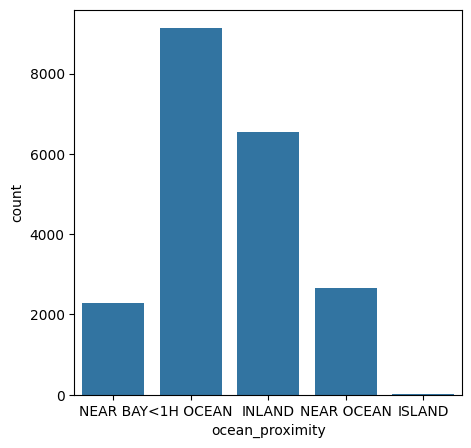

In [ ]:
for col in cat_cols:
  plt.figure(figsize=(5 , 5))
  sns.countplot(x = col , data = df)
  plt.show()

In [ ]:
df[cat_cols].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


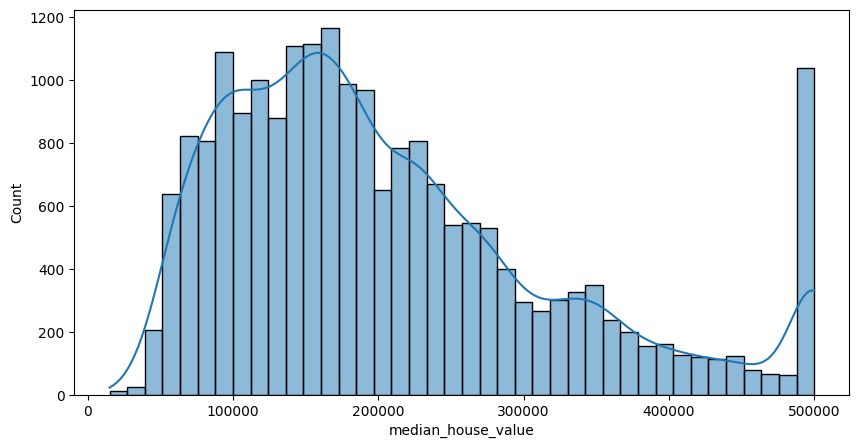

In [ ]:
plt.figure(figsize = (10 , 5))
sns.histplot(df["median_house_value"] , bins = 40 , kde = True)
plt.show()

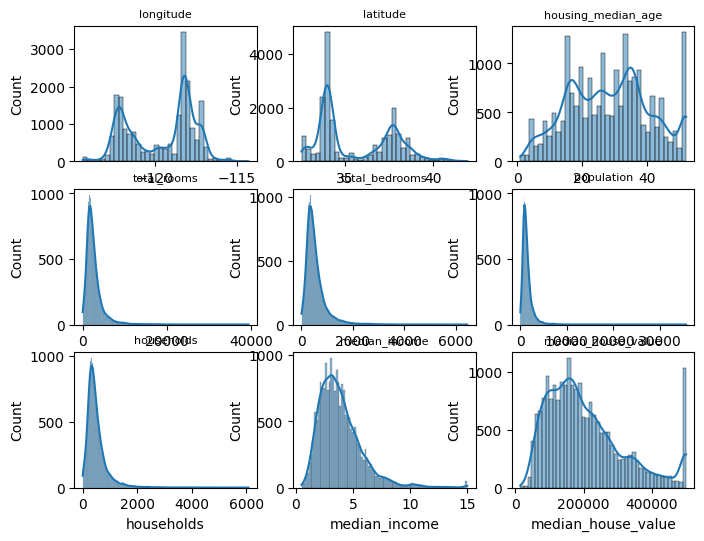

In [ ]:
fig , axes = plt.subplots(3 , 3 , figsize = (8 , 6))
axes = axes.flatten()


for i , col in enumerate(num_cols):
  sns.histplot(df[col] , kde = True , ax = axes[i])
  axes[i].set_title(col , fontsize = 8)

plt.show()

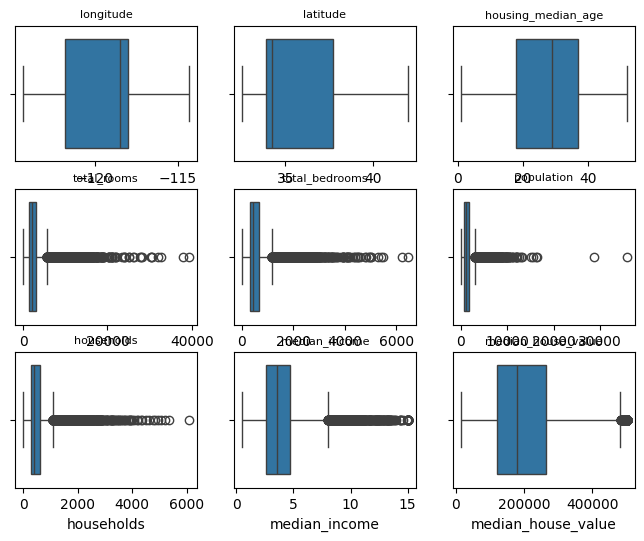

In [ ]:
fig , axes = plt.subplots(3 , 3 , figsize = (8 , 6))
axes = axes.flatten()


for i , col in enumerate(num_cols):
  sns.boxplot(x = df[col] , ax = axes[i])
  axes[i].set_title(col , fontsize = 8)

plt.show()

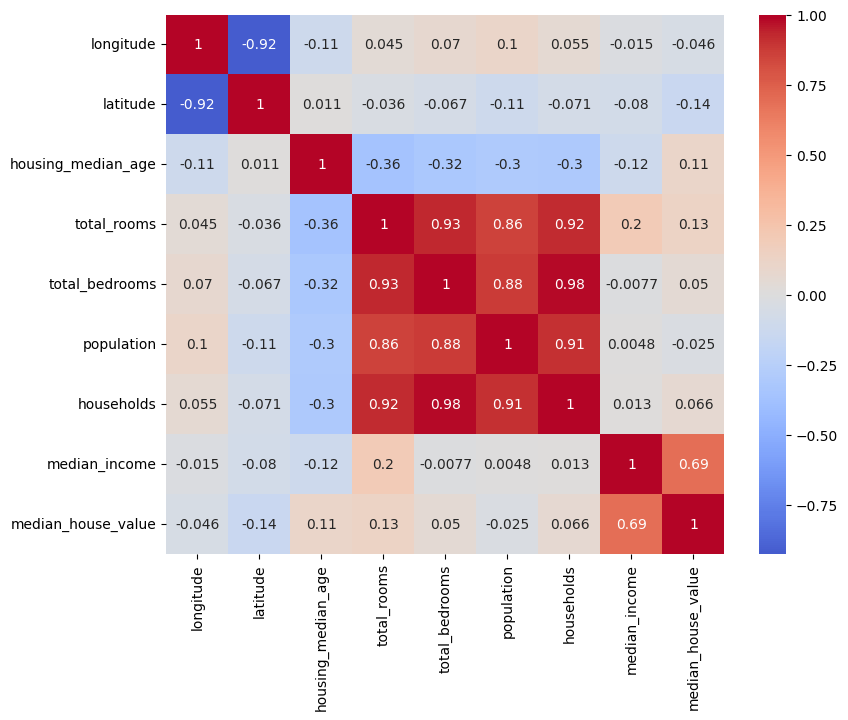

In [ ]:
plt.figure(figsize = (9 , 7))
sns.heatmap(
    df[num_cols].corr(),
    annot = True,
    cmap = "coolwarm",
    center = 0
)

plt.show()

In [ ]:
X = df.drop(columns ="median_house_value")
y = df["median_house_value"]

In [ ]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,NEAR BAY


In [ ]:
y.head()

,median_house_value
0,452600.000
1,358500.000
2,352100.000
3,341300.000
4,342200.000


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
#preprocessing Pipeline
numerical_columns = X_train.select_dtypes(include = [np.number]).columns.tolist()
categorical_columns = X_train.select_dtypes(include = "object").columns.tolist()
print(numerical_columns)
print(categorical_columns)

['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
['ocean_proximity']


In [ ]:
numeric_tranformer = Pipeline(
    [
        ("impute" , SimpleImputer(strategy="median")),
        ("Scaler" , StandardScaler())
    ]
)
categorical_tranformer = Pipeline(
    [
        ("impute" , SimpleImputer(strategy="most_frequent")),
        ("onehot" , OneHotEncoder(handle_unknown = "ignore"))
    ]
)


preprocess = ColumnTransformer(
    transformers = [
        ("num" , numeric_tranformer , numerical_columns),
        ("cat" , categorical_tranformer , categorical_columns)
    ]
)

In [ ]:
baseline_pipe = Pipeline(
    [
        ("preprocess" , preprocess),
        ("model" , LinearRegression())
    ]
)

In [ ]:
baseline_pipe.fit(X_train , y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ocean_proximity'])])),
                ('model', LinearRegression())])

In [ ]:
train_baseline_pred = baseline_pipe.predict(X_train)

In [ ]:
test_baseline_pred = baseline_pipe.predict(X_test)

In [ ]:
rmse_train = root_mean_squared_error(y_train , train_baseline_pred)
mae_train = mean_absolute_error(y_train , train_baseline_pred)
r2score_train = r2_score(y_train , train_baseline_pred)
print(rmse_train)
print(mae_train)
print(r2score_train)

68433.93736666226
49594.84209472437
0.6496648627123223


In [ ]:
rmse_test = root_mean_squared_error(y_test , test_baseline_pred)
mae_test = mean_absolute_error(y_test , test_baseline_pred)
r2score_test = r2_score(y_test, test_baseline_pred)
print(rmse_test)
print(mae_test)
print(r2score_test)

70059.19333925014
50670.48923565361
0.6254382675296266


In [ ]:
#so the model is a bit underfitted so we will now apply ridge and lasso

In [ ]:
models= {
    "LinearRegression" : LinearRegression(),
    "Ridge" : Ridge(random_state=42),
    "Lasso" : Lasso(random_state=42 ,max_iter = 10000),
    "RandomForestRegressor" : RandomForestRegressor(),
    "HistGB" : HistGradientBoostingRegressor()
}

In [ ]:
k = 5
cv = KFold(n_splits = k , shuffle = True , random_state = 42)

In [ ]:
scoring = {
    "rmse" : "neg_root_mean_squared_error",
    "mae" : "neg_mean_absolute_error",
    "r2" : "r2"
}

In [ ]:
rows = []

for name , model in models.items():
    pipe = Pipeline(
        [
            ("preprocess" , preprocess),
            ("model" , model)
        ]
    )
    scores = cross_validate(pipe , X_train , y_train , cv = cv , scoring = scoring , n_jobs = 1)
    rows.append({
        "model": name,
        "cv_rmse" : -scores["test_rmse"].mean(),
        "cv_mae" : -scores["test_mae"].mean(),
        "cv_r2" : -scores["test_r2"].mean()
    })

    cv_result = pd.DataFrame(rows).sort_values("cv_rmse")
    print(cv_result)


              model   cv_rmse    cv_mae  cv_r2
0  LinearRegression 68604.163 49667.159 -0.648
              model   cv_rmse    cv_mae  cv_r2
1             Ridge 68595.617 49664.331 -0.648
0  LinearRegression 68604.163 49667.159 -0.648
              model   cv_rmse    cv_mae  cv_r2
1             Ridge 68595.617 49664.331 -0.648
2             Lasso 68603.233 49667.263 -0.648
0  LinearRegression 68604.163 49667.159 -0.648


In [ ]:
hgb_pipeline = Pipeline(
    [
        ("preprocess" , preprocess),
        ("model" , HistGradientBoostingRegressor(random_state = 42))
    ]
)



In [113]:
param_grid = {
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_iter": [100, 200],
    "model__max_leaf_nodes": [15, 31],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [10, 20],
    "model__l2_regularization": [0.0, 0.1],
    "model__max_bins": [128, 255],
}

In [114]:
grid = GridSearchCV(
    estimator = hgb_pipeline ,
    param_grid = param_grid,
    cv = cv,
    scoring = "neg_root_mean_squared_error",
    n_jobs = 1,
    verbose = 1
)

In [115]:
grid.fit(X_train , y_train)

Fitting 5 folds for each of 288 candidates, totalling 1440 fits


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocess',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('impute',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('Scaler',
                                                                                          StandardScaler())]),
                                                                         ['longitude',
                                                                          'latitude',
                                                                          'housing_median_age',
                                                                          'total_rooms',
                                                                          'total_bedrooms',
                                                                          'population',
                                                                          'households',
                                                                          'median_income']...
                                       ('model',
                                        HistGradientBoostingRegressor(random_state=42))]),
             n_jobs=1,
             param_grid={'model__l2_regularization': [0.0, 0.1],
                         'model__learning_rate': [0.01, 0.05, 0.1],
                         'model__max_bins': [128, 255],
                         'model__max_depth': [None, 5, 10],
                         'model__max_iter': [100, 200],
                         'model__max_leaf_nodes': [15, 31],
                         'model__min_samples_leaf': [10, 20]},
             scoring='neg_root_mean_squared_error', verbose=1)

In [116]:
print(-grid.best_score_)
print(grid.best_params_)

47428.47567457199
{'model__l2_regularization': 0.1, 'model__learning_rate': 0.1, 'model__max_bins': 255, 'model__max_depth': 10, 'model__max_iter': 200, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 20}


In [119]:
hgb_best = Pipeline(
    [
        ("preprocess" , preprocess),
        ("model" , HistGradientBoostingRegressor(
            l2_regularization= 0.1,
            learning_rate= 0.1,
            max_bins= 255,
            max_depth= 10,
            max_iter= 200,
            max_leaf_nodes= 31,
            min_samples_leaf= 20
        ))
    ]
)

In [120]:
hgb_best.fit(X_train , y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('Scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ocean_proximity'])])),
                ('model',
                 HistGradientBoostingRegressor(l2_regularization=0.1,
                                               max_depth=10, max_iter=200))])

In [121]:
train_final_pred = hgb_best.predict(X_train)

final_rmse_train = root_mean_squared_error(y_train , train_final_pred)
final_mae_train = mean_absolute_error(y_train , train_final_pred)
final_r2_train = r2_score(y_train, train_final_pred)
print(final_rmse_train)
print(final_mae_train)
print(final_r2_train)

36916.04777078191
25199.304309257564
0.8980538004737226


In [122]:
test_final_pred = hgb_best.predict(X_test)

final_rmse_test = root_mean_squared_error(y_test , test_final_pred)
final_mae_test = mean_absolute_error(y_test , test_final_pred)
final_r2_test = r2_score(y_test, test_final_pred)
print(final_rmse_test)
print(final_mae_test)
print(final_r2_test)

46487.08908749589
31004.93639694334
0.8350858787056096


In [126]:
import numpy as np
import pandas as pd


def predict_house_price(
    model,
    longitude: float,
    latitude: float,
    housing_median_age: float,
    total_rooms: float,
    total_bedrooms: float,
    population: float,
    households: float,
    median_income: float,
    ocean_proximity: str
) -> float:

    new_row = pd.DataFrame([{
        "longitude": longitude,
        "latitude": latitude,
        "housing_median_age": housing_median_age,
        "total_rooms": total_rooms,
        "total_bedrooms": total_bedrooms,
        "population": population,
        "households": households,
        "median_income": median_income,
        "ocean_proximity": ocean_proximity
    }])

    return float(model.predict(new_row)[0])

In [127]:

example_pred = predict_house_price(
    model=hgb_best,
    longitude=-122.230,
    latitude=37.880,
    housing_median_age=41,
    total_rooms=880,
    total_bedrooms=129,
    population=322,
    households=126,
    median_income=8.3252,
    ocean_proximity="NEAR BAY"
)

print("\nExample prediction:", round(example_pred, 2))


Example prediction: 456078.69
